In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/My Drive/ciencias de dados/melb_data.csv'

Mounted at /content/drive


In [5]:
df = pd.read_csv(path)

In [6]:
df.head()

,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [7]:
print("DIMENSÕES DO DATASET")
print(df.shape)

print("\nTIPO DE CADA COLUNA")
print(df.dtypes)

print("\nQUANTIDADE DE VALORES AUSENTES")
print(df.isnull().sum())

DIMENSÕES DO DATASET
(13580, 21)

TIPO DE CADA COLUNA
Suburb            object
Address           object
Rooms              int64
Type              object
Price            float64
Method            object
SellerG           object
Date              object
Distance         float64
Postcode         float64
Bedroom2         float64
Bathroom         float64
Car              float64
Landsize         float64
BuildingArea     float64
YearBuilt        float64
CouncilArea       object
Lattitude        float64
Longtitude       float64
Regionname        object
Propertycount    float64
dtype: object

QUANTIDADE DE VALORES AUSENTES
Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
L

In [8]:
ausentes = df.isnull().sum()

resumo_ausentes = pd.DataFrame({
    'Quantidade de ausentes': ausentes,
    'Porcentagem de ausentes (%)': (ausentes / len(df)) * 100
})

# Manter apenas as colunas que possuem valores ausentes
resumo_ausentes = resumo_ausentes[
    resumo_ausentes['Quantidade de ausentes'] > 0
]

# Ordenar da maior para a menor quantidade de ausentes
resumo_ausentes = resumo_ausentes.sort_values(
    by='Quantidade de ausentes',
    ascending=False
)

resumo_ausentes

,Quantidade de ausentes,Porcentagem de ausentes (%)
BuildingArea,6450,47.496318
YearBuilt,5375,39.580265
CouncilArea,1369,10.081001
Car,62,0.456554


In [9]:
!pip install missingno

In [10]:
import missingno as msno

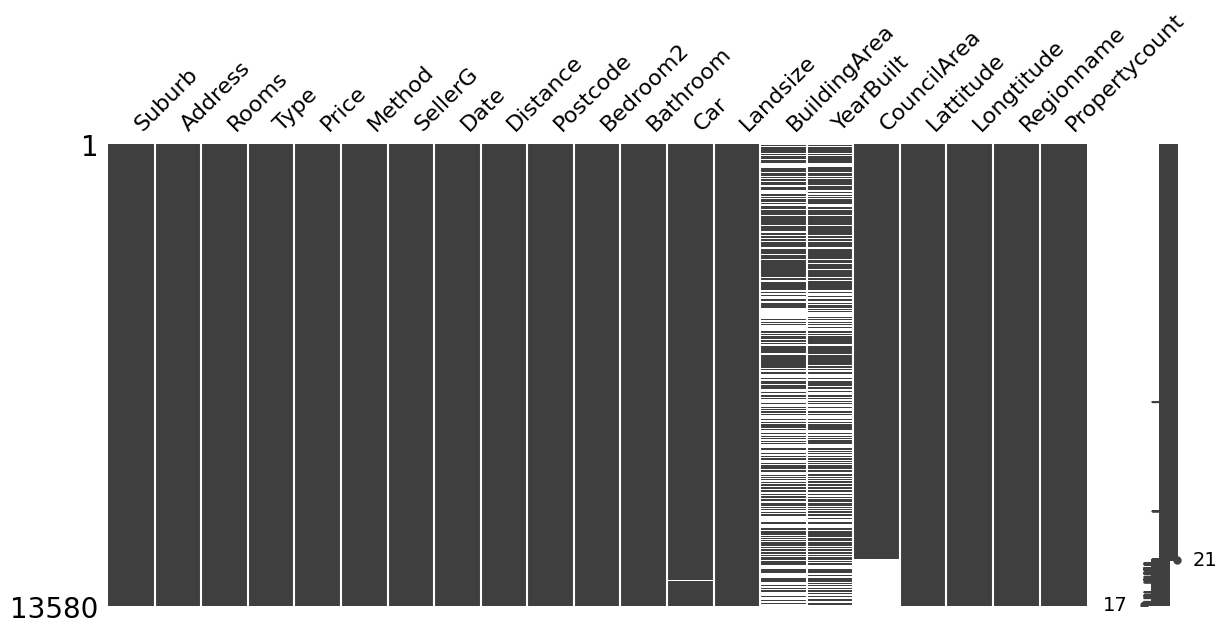

In [11]:
msno.matrix(df, figsize=(14, 6))
plt.show()

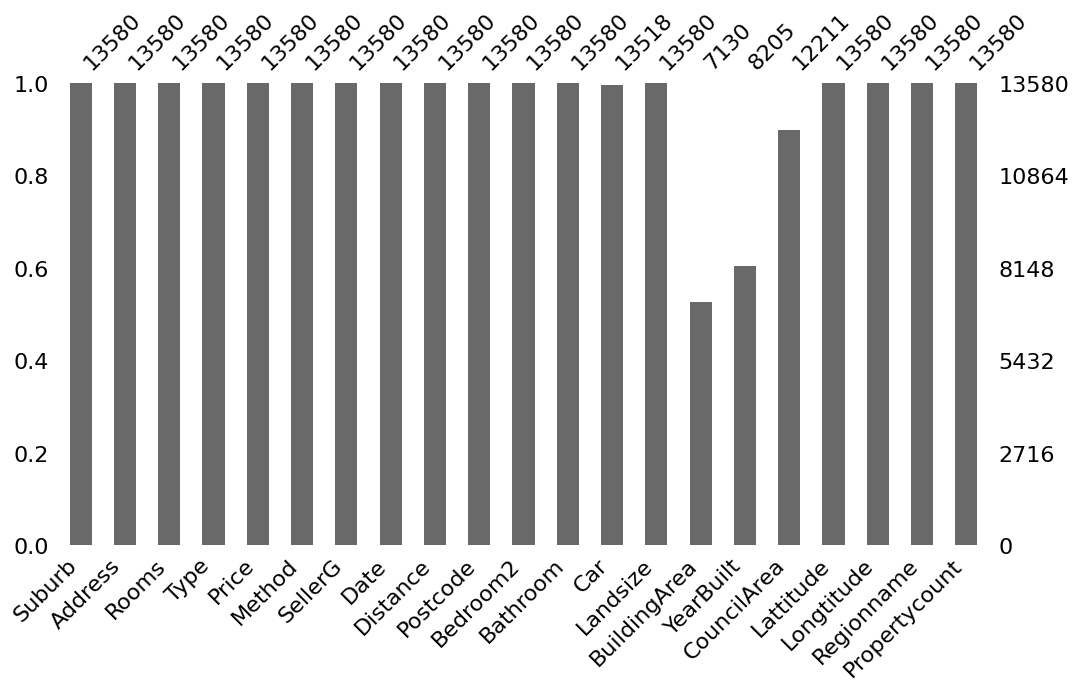

In [12]:
msno.bar(df, figsize=(12, 6))
plt.show()

Os valores ausentes estão concentrados principalmente em algumas colunas, enquanto outras apresentam poucos ou nenhum valor faltante. Pela visualização do padrão de ausência, também é possível observar que algumas linhas apresentam ausência simultânea em mais de uma variável.

In [13]:
df['Landsize'].describe()

,Landsize
count,13580.000000
mean,558.416127
std,3990.669241
min,0.000000
25%,177.000000
50%,440.000000
75%,651.000000
max,433014.000000


In [14]:
df_remocao = df.copy()

df_remocao = df_remocao.dropna(subset=['Landsize'])

print("Linhas no dataset original:", len(df))
print("Linhas após remoção:", len(df_remocao))
print("Linhas removidas:", len(df) - len(df_remocao))

Linhas no dataset original: 13580
Linhas após remoção: 13580
Linhas removidas: 0


In [15]:
df_imputacao = df.copy()

In [16]:
mediana_landsize = df_imputacao['Landsize'].median()

print("Mediana de Landsize:", mediana_landsize)

Mediana de Landsize: 440.0
